<a href="https://colab.research.google.com/github/vaishnavbkurup/healthcare-analytics-doctor-visits/blob/main/healthcare-analytics-doctor-visits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload your CSV dataset file:


Saving 1776250375-P2-Healthcare Analytics for Doctor Visits (2).csv to 1776250375-P2-Healthcare Analytics for Doctor Visits (2).csv

--- FILE LOADED SUCCESSFULLY! ---
File Name: 1776250375-P2-Healthcare Analytics for Doctor Visits (2).csv
Total Records (Rows): 5190
Total Columns: 13



,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no



--- SUMMARY STATISTICS ---
            visits          age       income      illness      reduced  \
count  5190.000000  5190.000000  5190.000000  5190.000000  5190.000000   
mean      0.301734     0.406385     0.583160     1.431985     0.861850   
std       0.798134     0.204782     0.368907     1.384152     2.887628   
min       0.000000     0.190000     0.000000     0.000000     0.000000   
25%       0.000000     0.220000     0.250000     0.000000     0.000000   
50%       0.000000     0.320000     0.550000     1.000000     0.000000   
75%       0.000000     0.620000     0.900000     2.000000     0.000000   
max       9.000000     0.720000     1.500000     5.000000    14.000000   

            health  
count  5190.000000  
mean      1.217534  
std       2.124266  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       2.000000  
max      12.000000  

--- KEY ANALYTICAL INSIGHTS ---

Average Doctor Visits by Gender:
gender
female    0.361954
male      0.236334
Name

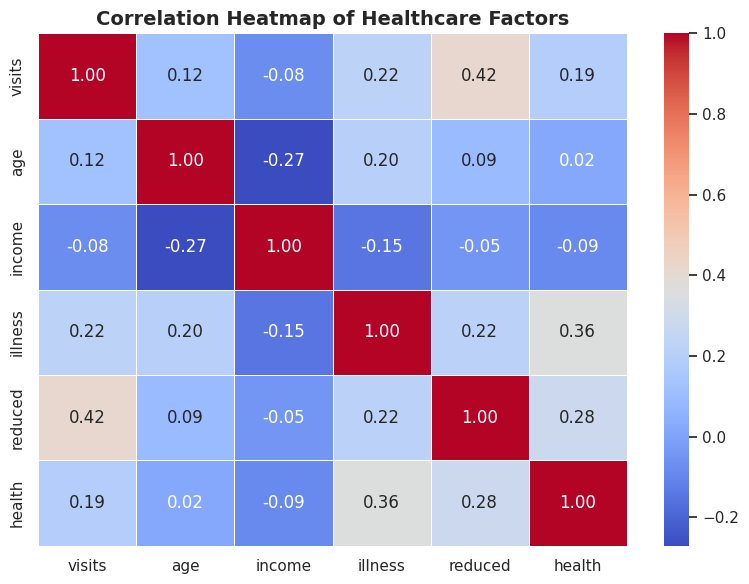

/tmp/ipykernel_3702/3474509552.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="visits", data=df, palette="Blues_d")


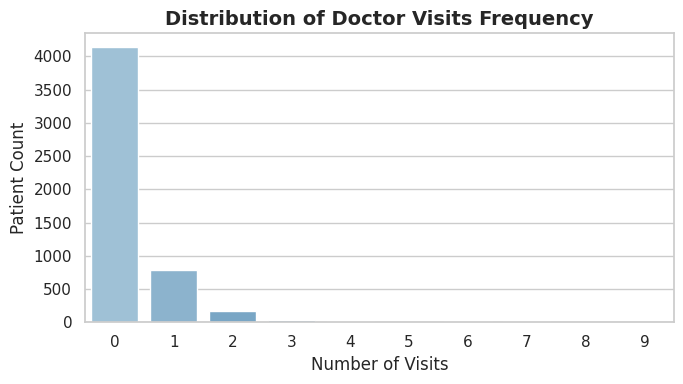

/tmp/ipykernel_3702/3474509552.py:73: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x="illness", y="visits", data=df, ci=None, palette="viridis")
/tmp/ipykernel_3702/3474509552.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="illness", y="visits", data=df, ci=None, palette="viridis")


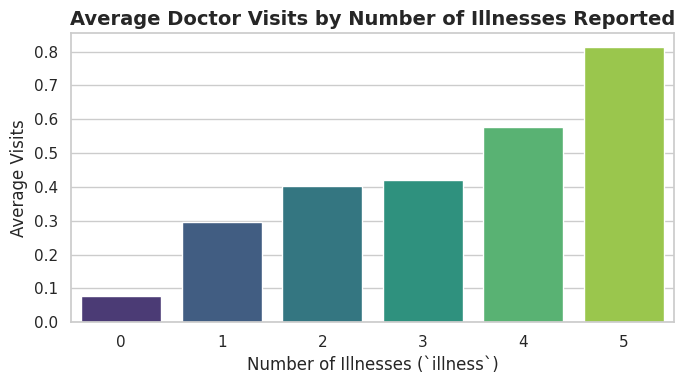


All charts have been displayed and automatically saved to your Colab environment files!


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files

# Set visual style for plots
sns.set_theme(style="whitegrid")

# 1. Upload file interactively in Google Colab
print("Please upload your CSV dataset file:")
uploaded = files.upload()

# Retrieves the filename automatically and loads the CSV
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("\n--- FILE LOADED SUCCESSFULLY! ---")
print(f"File Name: {file_name}")
print(f"Total Records (Rows): {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}\n")

# Display first few rows
display(df.head())

# 2. Descriptive Statistics
print("\n--- SUMMARY STATISTICS ---")
numeric_cols = ["visits", "age", "income", "illness", "reduced", "health"]
print(df[numeric_cols].describe())

# 3. Key Analytical Insights
print("\n--- KEY ANALYTICAL INSIGHTS ---")
visits_by_gender = df.groupby("gender")["visits"].mean()
print("\nAverage Doctor Visits by Gender:")
print(visits_by_gender)

visits_by_insurance = df.groupby("private")["visits"].mean()
print("\nAverage Doctor Visits by Private Insurance (`private`):")
print(visits_by_insurance)

# 4. Data Visualization & Chart Generation
# Figure 1: Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title(
    "Correlation Heatmap of Healthcare Factors", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

# Figure 2: Distribution of Doctor Visits
plt.figure(figsize=(7, 4))
sns.countplot(x="visits", data=df, palette="Blues_d")
plt.title(
    "Distribution of Doctor Visits Frequency", fontsize=14, fontweight="bold"
)
plt.xlabel("Number of Visits", fontsize=12)
plt.ylabel("Patient Count", fontsize=12)
plt.tight_layout()
plt.savefig("visits_distribution.png", dpi=300)
plt.show()

# Figure 3: Relationship between Illnesses and Doctor Visits
plt.figure(figsize=(7, 4))
sns.barplot(x="illness", y="visits", data=df, ci=None, palette="viridis")
plt.title(
    "Average Doctor Visits by Number of Illnesses Reported",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Number of Illnesses (`illness`)", fontsize=12)
plt.ylabel("Average Visits", fontsize=12)
plt.tight_layout()
plt.savefig("illness_vs_visits.png", dpi=300)
plt.show()

print(
    "\nAll charts have been displayed and automatically saved to your Colab environment files!"
)